In [13]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import solve_ivp

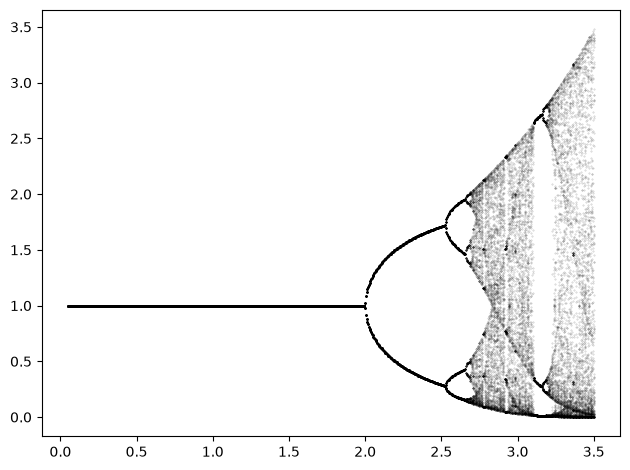

In [14]:
def ricker(B,r,K):
    return(B*np.exp(r*(1-B/K)))
r_values = np.linspace(0.05,3.5,700)
B0 = 0.5
K = 1
plot_r = []
plot_B = []
for r_value in r_values:
    B = B0
    for j in range(1000):
        B = ricker(B,r_value,K)
        if j > 900:
            plot_r.append(r_value)
            plot_B.append(B)
plt.scatter(plot_r,plot_B,s=0.1,color = "black", alpha = 0.25)
plt.tight_layout()

/tmp/ipykernel_1366/2673816355.py:2: RuntimeWarning: overflow encountered in exp
  return(B*np.exp(r*(1-B/K))-q*E*B)
/tmp/ipykernel_1366/2673816355.py:2: RuntimeWarning: invalid value encountered in scalar subtract
  return(B*np.exp(r*(1-B/K))-q*E*B)


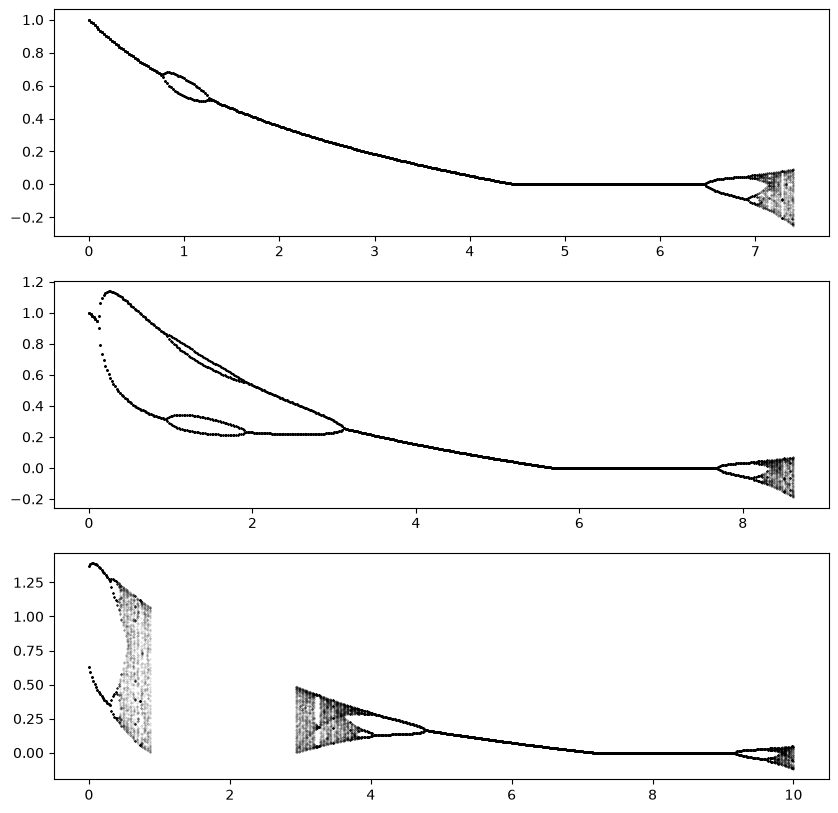

In [15]:
def ricker_harvesting(B,r,K,q,E):
    return(B*np.exp(r*(1-B/K))-q*E*B)
E_values = np.linspace(0,10,501)
B0 = 0.01
K = 1
r_values = [1.7,1.9,2.1]
q = 1


fig,ax = plt.subplots(3,1,figsize=(10,10))
for index,r_value in enumerate(r_values):
    plot_E = []
    plot_B = []
    for E_value in E_values:
        B = B0
        for j in range(1000):
            B = ricker_harvesting(B,r_value,K,q,E_value)
            if j > 900:
                plot_E.append(E_value)
                plot_B.append(B)
    ax[index].scatter(plot_E,plot_B,s=0.1,color = "black", alpha = 0.25)

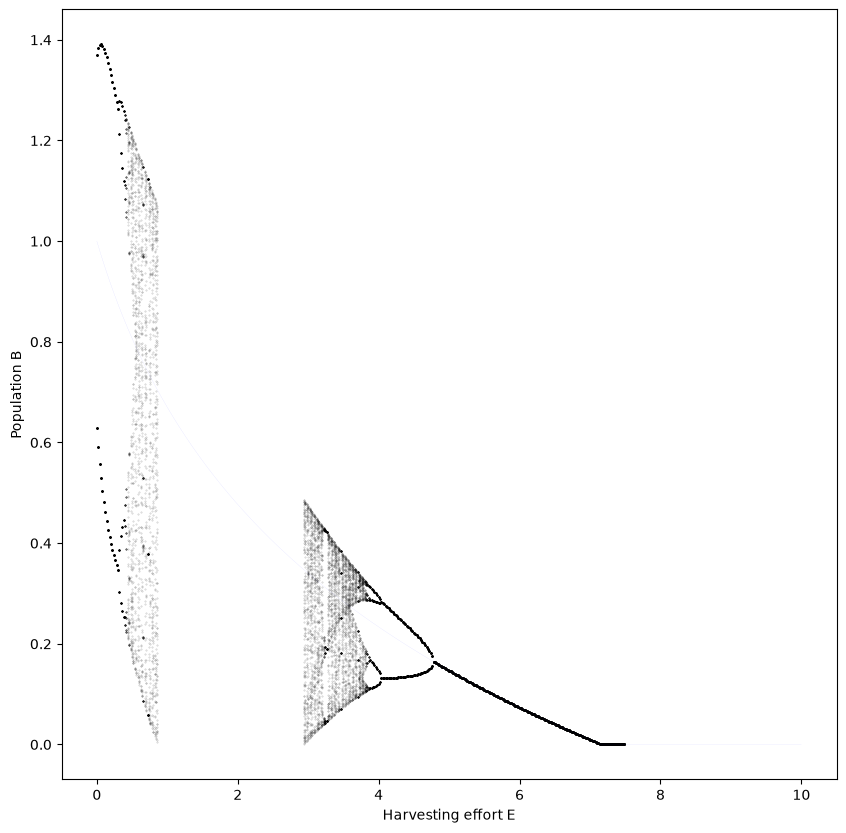

In [ ]:
def ricker_harvesting(B,r,K,q,E):
    return(B*np.exp(r*(1-B/K))-q*E*B)
E_values = np.linspace(0,10,501)
B0 = 0.01
K = 1
r_values = [2.1]
q = 1
def B_max(K,q,E,r):
    return(-K*(math.log(((q*E)-1)/r)))

fig,ax = plt.subplots(3,1,figsize=(10,10))
for index,r_value in enumerate(r_values):
    plot_E = []
    plot_B = []
    plot_B_max = []
    plot_e_2 = []
    for E_value in E_values:
        B = B0
        plot_B_max.append(B_max(K,q,E_value,r_value))
        plot_e_2.append(E_value)
        for j in range(5000):
            B = ricker_harvesting(B,r_value,K,q,E_value)
            if j > 9900:
                plot_E.append(E_value)
                plot_B.append(B)
    ax[index].scatter(plot_E,plot_B,s=0.1,color = "black", alpha = 0.25)
    ax[index].plot(plot_e_2,plot_B_max,s=0.1,color = "blue", alpha = 0.25)

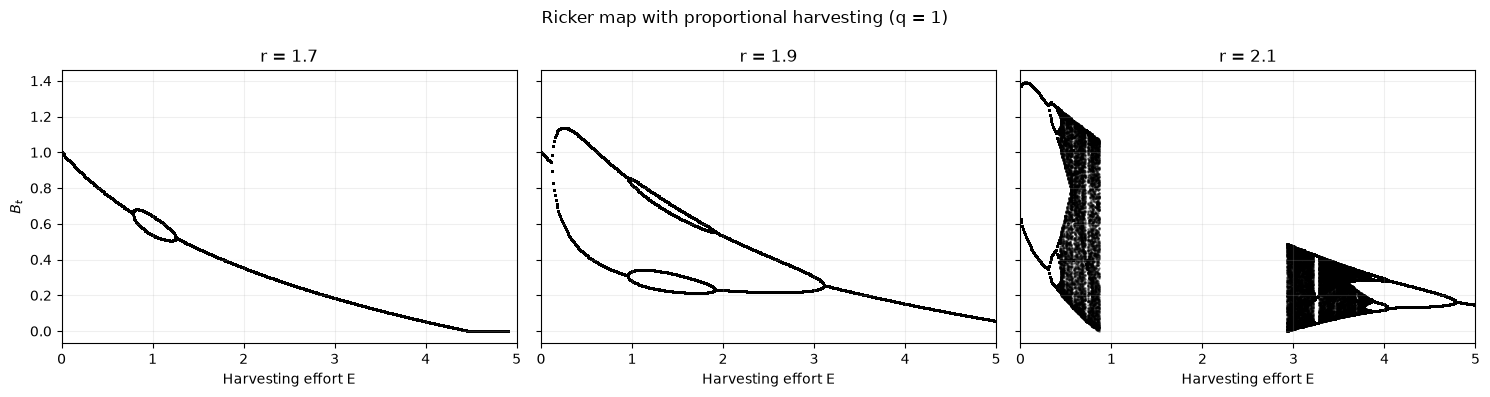

In [17]:
import numpy as np
import matplotlib.pyplot as plt

def ricker_harvesting(B, r, K, q, E):
    return B * np.exp(r * (1 - B / K)) - q * E * B

E_values = np.linspace(0.001, 5, 501)  # E in (0, 5)
r_values = [1.7, 1.9, 2.1]
K = 1
q = 1
B0 = 0.01

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, r_value in zip(axes, r_values):
    plot_E = []
    plot_B = []

    for E_value in E_values:
        B = B0

        # Iterate the map, then plot the settled orbit values
        for j in range(1500):
            B = ricker_harvesting(B, r_value, K, q, E_value)

            # Stop if the population becomes non-positive or non-finite
            if not np.isfinite(B) or B <= 0:
                break

            if j >= 1300:
                plot_E.append(E_value)
                plot_B.append(B)

    ax.scatter(plot_E, plot_B, s=1, color="black", alpha=0.35)
    ax.set_title(f"r = {r_value}")
    ax.set_xlabel("Harvesting effort E")
    ax.set_xlim(0, 5)
    ax.grid(alpha=0.2)

axes[0].set_ylabel(r"$B_t$")
fig.suptitle("Ricker map with proportional harvesting (q = 1)")
fig.tight_layout()
plt.show()


In [ ]:
def ricker_depensation(B, r, K, A):
    return B * np.exp(r * (1 - B / K) * (B / A - 1))

A = 0.4
K = 1
B0 = 0.8

In [ ]:
r_values = [2, 2.2, 2.25]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, r_value in zip(axes, r_values):
    plot_t = []
    plot_B = []
    B = B0

    for i in range(100):
        B = ricker_depensation(B, r_value, K, A)
        if not np.isfinite(B) or B < 0:
            break

        if i >= 50:
            plot_t.append(i)
            plot_B.append(B)

    ax.plot(plot_t, plot_B)
    ax.set_title(f"r = {r_value}")
    ax.set_xlabel("Generation t")

axes[0].set_ylabel("Population B")
fig.tight_layout()
plt.show()

SyntaxError: incomplete input (874137176.py, line 7)